### Data Quality Analysis
This notebook covers all the possible data quality checks like missing values, invalid values, duplicates and outliers

#### Imports and Load

In [10]:
# Importing necessary libraries for the data quality analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('../data/raw/ChargingRecords.csv')
df.shape

(72856, 13)

#### Section:1 Missing values, Data types and unique counts

In [4]:
# Checking nulls in each column
df.isnull().sum()

UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64

In [6]:
# Checking dtypes of each column
df.dtypes

UserID              int64
ChargerID           int64
ChargerCompany      int64
Location           object
ChargerType         int64
StartDay           object
StartTime          object
EndDay             object
EndTime            object
StartDatetime      object
EndDatetime        object
Duration            int64
Demand            float64
dtype: object

In [18]:
# Checking how many date columns rows cannot be converted properly to datetime format
start_test=pd.to_datetime(df['StartDatetime'], errors='coerce')
start_test.isna().sum()

np.int64(0)

In [12]:
end_test=pd.to_datetime(df['EndDatetime'],errors='coerce')
end_test.isna().sum()

np.int64(0)

In [7]:
# Checking the unique values
df.nunique()

UserID             2337
ChargerID          2119
ChargerCompany        2
Location             14
ChargerType           2
StartDay            366
StartTime         43245
EndDay              365
EndTime           46710
StartDatetime     65628
EndDatetime       66745
Duration            979
Demand             6046
dtype: int64

#### Section:2 Duplicates

In [13]:
# Checking the duplicate count
df.duplicated().sum()

np.int64(13)

In [16]:
# Checking which rows are duplicated
df[df.duplicated(keep=False)].sort_values(['UserID', 'StartDatetime'])

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
66120,156,1450,0,public parking lot,1,2022-02-21,12:03:16,2022-02-21,12:43:16,2022-02-21 12:03,2022-02-21 12:43,40,13.56
66121,156,1450,0,public parking lot,1,2022-02-21,12:03:16,2022-02-21,12:43:16,2022-02-21 12:03,2022-02-21 12:43,40,13.56
60211,228,1045,0,public area,1,2022-02-26,18:24:08,2022-02-26,18:39:59,2022-02-26 18:24,2022-02-26 18:39,16,10.54
60212,228,1045,0,public area,1,2022-02-26,18:24:08,2022-02-26,18:39:59,2022-02-26 18:24,2022-02-26 18:39,16,10.54
51498,276,640,0,company,1,2022-02-26,9:23:02,2022-02-26,10:03:07,2022-02-26 9:23,2022-02-26 10:03,40,15.04
51499,276,640,0,company,1,2022-02-26,9:23:02,2022-02-26,10:03:07,2022-02-26 9:23,2022-02-26 10:03,40,15.04
28856,329,214,1,public area,0,2022-02-12,7:22:40,2022-02-12,15:44:27,2022-02-12 7:22,2022-02-12 15:44,502,54.34
28857,329,214,1,public area,0,2022-02-12,7:22:40,2022-02-12,15:44:27,2022-02-12 7:22,2022-02-12 15:44,502,54.34
28858,329,214,1,public area,0,2022-02-15,19:29:42,2022-02-15,23:03:11,2022-02-15 19:29,2022-02-15 23:03,213,23.68
28859,329,214,1,public area,0,2022-02-15,19:29:42,2022-02-15,23:03:11,2022-02-15 19:29,2022-02-15 23:03,213,23.68


In [ ]:
# Checking duplicate sessions (user_id, charger_id and start_datetime
df.duplicated(subset=['UserID', 'ChargerID', 'StartDatetime']).sum()

np.int64(34)

In [19]:
# Checking the above hidden duplicated sessions excluding complete duplicates

# This shows all these 34 duplicates inclduing hidden duplicates and exact duplicates
key_dups = df[df.duplicated(subset= ['UserID', 'ChargerID', 'StartDatetime'], keep=False)]

# This shows only hidden duplicates
hidden_dups = key_dups[~key_dups.duplicated(keep=False)]

hidden_dups.sort_values(['UserID', 'ChargerID', 'StartDatetime'])

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
2160,0,13,1,apartment,0,2022-08-20,19:01:27,2022-08-21,5:10:12,2022-08-20 19:01,2022-08-21 5:10,165,8.70
2161,0,13,1,apartment,0,2022-08-20,19:01:40,2022-08-21,5:07:22,2022-08-20 19:01,2022-08-21 5:07,606,8.70
4283,0,20,1,resort,0,2022-07-06,19:54:34,2022-07-07,6:10:26,2022-07-06 19:54,2022-07-07 6:10,348,24.70
4284,0,20,1,resort,0,2022-07-06,19:54:42,2022-07-07,6:08:41,2022-07-06 19:54,2022-07-07 6:08,614,24.70
5146,0,22,1,hotel,0,2022-07-23,18:26:34,2022-07-24,5:10:05,2022-07-23 18:26,2022-07-24 5:10,643,42.10
5147,0,22,1,hotel,0,2022-07-23,18:26:46,2022-07-24,5:09:21,2022-07-23 18:26,2022-07-24 5:09,643,42.10
6361,0,26,1,public area,0,2022-08-13,23:40:05,2022-08-13,23:59:50,2022-08-13 23:40,2022-08-13 23:59,20,2.17
6362,0,26,1,public area,0,2022-08-13,23:40:05,2022-08-13,23:59:49,2022-08-13 23:40,2022-08-13 23:59,20,2.17
7683,0,30,1,resort,0,2022-02-03,9:44:09,2022-02-03,9:44:14,2022-02-03 9:44,2022-02-03 9:44,0,0.01
7684,0,30,1,resort,0,2022-02-03,9:44:49,2022-02-03,10:44:31,2022-02-03 9:44,2022-02-03 10:44,60,6.80


#### Section 3: Inconsistent/Invalid Values

#### Section-3a: Do StartDate + StartTime match StartDatetime?
If StartDate and StartTime columns match with StateDateTime we can remove those two columns as they are redundant. So here I'm checking whether both redundant columns match or not for all the rows.


In [20]:
# Combined Start Day and Start Time
start_combined = pd.to_datetime(df['StartDay'] + ' ' + df['StartTime'])

# Given Start Datetime
start_given = pd.to_datetime(df['StartDatetime'])

# Caluclating the gap between combined and given columns which gives only seconds difference.
start_gap = (start_combined - start_given).dt.total_seconds() / 60

# If the gap is more than 1 minute then the columns did not match
(start_gap.abs() >= 1).sum()

np.int64(0)

In [21]:
# Same procedure for the EndDate columns
end_combined = pd.to_datetime(df['EndDay'] + ' ' + df['EndTime'])
end_given = pd.to_datetime(df['EndDatetime'])
end_gap = (end_combined - end_given).dt.total_seconds() / 60
(end_gap.abs() >= 1).sum()

np.int64(0)

#### Section-3b: Negative Duration

In [23]:
# Checking how many instances are giving negative duration (end time before start time)
(df['Duration'] < 0).sum()

np.int64(17)

In [25]:
# Checking which rows have these negative duration
df[df['Duration'] < 0]

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
55422,1403,775,0,market,1,2022-02-15,15:04:54,2022-02-15,14:35:36,2022-02-15 15:04,2022-02-15 14:35,-29,11.68
55425,1403,775,0,market,1,2022-02-24,14:27:44,2022-02-24,14:18:35,2022-02-24 14:27,2022-02-24 14:18,-9,34.56
55427,1403,775,0,market,1,2022-01-17,14:47:03,2022-01-17,14:39:24,2022-01-17 14:47,2022-01-17 14:39,-8,17.77
55455,37,778,0,market,1,2022-04-29,18:58:46,2022-04-29,18:52:20,2022-04-29 18:58,2022-04-29 18:52,-6,31.90
55457,55,778,0,market,1,2022-05-07,16:24:20,2022-05-07,16:03:03,2022-05-07 16:24,2022-05-07 16:03,-21,13.39
55458,74,778,0,market,1,2022-04-29,15:48:51,2022-04-29,15:43:07,2022-04-29 15:48,2022-04-29 15:43,-6,19.36
55459,92,778,0,market,1,2022-03-27,15:17:53,2022-03-27,15:10:38,2022-03-27 15:17,2022-03-27 15:10,-7,20.99
55460,92,778,0,market,1,2022-02-05,18:52:39,2022-02-05,18:50:15,2022-02-05 18:52,2022-02-05 18:50,-2,31.59
55464,266,778,0,market,1,2022-05-08,12:02:28,2022-05-08,11:42:02,2022-05-08 12:02,2022-05-08 11:42,-20,3.28
55465,326,778,0,market,1,2022-01-09,14:29:15,2022-01-09,14:20:28,2022-01-09 14:29,2022-01-09 14:20,-9,31.68


#### Section-3c: Zero Duration

In [26]:
# Checking how many instances have zero duration
(df['Duration'] == 0).sum()

np.int64(718)

In [27]:
# Checking how much energy did these sessions use
df[df['Duration'] == 0]['Demand'].describe()

count    718.000000
mean       4.242368
std        9.488283
min        0.010000
25%        0.020000
50%        0.040000
75%        2.455000
max       62.400000
Name: Demand, dtype: float64

#### Section-3d: Does Duration match End-Start DateTimes?

In [34]:
# Calculating the duration from combined Start dateime and End datetime
calc_duration=(end_combined-start_combined).dt.total_seconds() / 60

In [35]:
# Comparing the gap between the given duration and the calcuated duration
duration_gap=(calc_duration - df['Duration']).abs()

(duration_gap < 1).sum(), (duration_gap >= 10).sum()

(np.int64(68569), np.int64(1926))

#### Section-3e: Impossible Charging Speeds

In [53]:
# Calculating the average power 
positive= df[df['Duration']>0]
power_kw= positive['Demand']/(positive['Duration']/60)
power_kw.describe()

count    72121.000000
mean        11.656055
std         15.847228
min          0.000534
25%          6.077419
50%          6.700000
75%          7.080000
max       1657.800000
dtype: float64

In [55]:
# Checking whether any instances have power >350kwh (Because anything above this will be considered as impossible charging speeds)
(power_kw>350).sum()

np.int64(8)

#### Section-3f: Category and value checks

In [42]:
# Checking all the unique values of the Location category to check for spelling mistakes or case sensitive duplicates
df['Location'].unique()

array(['hotel', 'company', 'apartment', 'resort', 'public area',
       'public institution', 'restaurant', 'accommodation', 'golf',
       'sightseeing', 'market', 'camping', 'public parking lot',
       'bus garage'], dtype=object)

In [44]:
# Checking all the unique values of the charger type and charger company category to check for spelling mistakes or case sensitive duplicates
df['ChargerType'].unique(), df['ChargerCompany'].unique()

(array([0, 1]), array([1, 0]))

In [47]:
# Checking all the min max values of the demand column to see for any 0 or negative demands
df['Demand'].min(), df['Demand'].max()


(np.float64(0.01), np.float64(97.0))

#### Section-3g: Date range and overnight sessions


In [50]:
# Checking and confirming the date ranges in the dataset
start_given.min(), start_given.max()

(Timestamp('2021-09-30 17:14:00'), Timestamp('2022-09-30 23:11:00'))

In [52]:
# Checking the instances for different start day and end days
(df['StartDay']!=df['EndDay']).sum()

np.int64(10828)

#### Section-4: Outliers Detection

In [57]:
# Checking the outliers presence using the describe
df[['Demand', 'Duration']].describe()

# Seeing where the 50% of the data lies and the max value, there are definitely outliers present in the dataset

,Demand,Duration
count,72856.000000,72856.000000
mean,17.444445,151.194054
std,13.492728,146.430286
min,0.010000,-29.000000
25%,7.530000,40.000000
50%,14.100000,112.000000
75%,23.200000,202.000000
max,97.000000,1573.000000


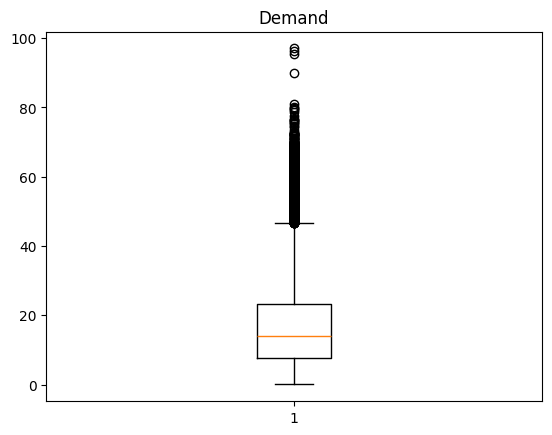

In [58]:
# Checking outliers in demand column
plt.boxplot(df['Demand'])
plt.title('Demand')
plt.show()

In [66]:
# Checking how many outliers are present in the demand column
q1= df['Demand'].quantile(0.25)
q3= df['Demand'].quantile(0.75)
iqr= q3 - q1
upper= q3+ 1.5*iqr

print('Upper limit:', upper)
print('Outliers:', (df['Demand'] > upper).sum())

Upper limit: 46.705
Outliers: 3444


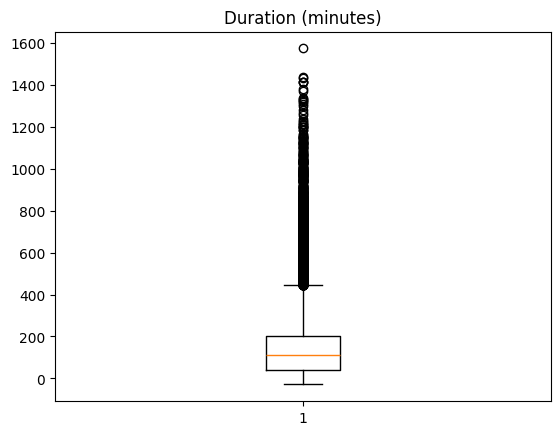

In [59]:
# Checking outliers for duration column
plt.boxplot(df['Duration'])
plt.title('Duration (minutes)')
plt.show()

In [67]:
# Checking how many outliers are present in the duration column
q1= df['Duration'].quantile(0.25)
q3= df['Duration'].quantile(0.75)
iqr= q3 - q1
upper= q3 + 1.5 * iqr

print('Upper limit:', upper)
print('Outliers:', (df['Duration']> upper).sum())

Upper limit: 445.0
Outliers: 3924


#### Observations:
1. There are no missing values and both the datetime columns can be converted to respective dtype without errors.
2. There are 13 exactly duplicate rows. Also, 21 sessions appear twice with the same user, charger and start time but slightly different end time or duration.
3. StartDay + StartTime and EndDay + EndTime match StartDatetime and EndDatetime (only the seconds differ), so these four columns are redundant and I’ll drop them.
4. 17 sessions have end time before start time. All of them are at market locations, so it looks like a recording errors.
5. 718 sessions have zero duration. Most of them have very small demand, so they look like failed or test sessions.
6. About 94% of rows have Duration matching (end − start) within a minute. Around 2.6% (1,926 rows) differ by 10 minutes or more. 
7. 8 sessions have a charging speed above 350 kW, which is not possible for any real charger, so these are invalid.
8. Location, ChargerType and ChargerCompany have clean values, and Demand has no zero or negative values.
9. About 10,800 sessions go past midnight. This is normal overnight charging, not an error.
10. By IQR rule, Demand has 3,444 outliers and Duration has 3,924. These look like long or heavy charging sessions, so I’ll keep them.